# 30-Day Readmission Risk: Final Pipeline v3
**India Hospital Readmission Dataset (2015-2024)** | binary classification of `readmitted_30d`

**What this notebook adds over the earlier ones**
1. **Fundamentals first:** data audit, leakage checklist, label sanity check, trivial baselines, then models.
2. **Time analysis:** volume and readmission rate by year / month / weekday, label-censoring check, gap-between-admissions view, feature drift (PSI), and rolling-origin validation.
3. **Balanced-data study:** none vs class weights vs under-sampling vs over-sampling, applied to the **training rows only**. The retrieval corpus and the validation/test sets keep their natural 12-13% prevalence.
4. **Richer feature-grounded notes** (no label information) so the retrieval step reads like real clinical text.
5. LR, RF and a fine-tuned Transformer, each **with and without** the RAG feature, with patient-cluster bootstrap CIs.
6. Operating points, calibration, risk bands, and **saved artifacts** ready for the FastAPI/Streamlit app.

**Leakage controls:** temporal split (train 2015-21 / val 2022 / test 2023-24); a neighbour is retrievable only if `discharge + 30 days < query admit date`; same-patient neighbours excluded; retrieval corpus = train + val only; thresholds and balancing choice picked on validation only.

Set `MODE = 'quick'` first (a smoke test), then `'full'`. Use a GPU runtime (T4) for the embedding and Transformer steps.

## 0. Install (Colab). Skip lines you already have.

In [1]:
# !pip -q install kagglehub scikit-learn pandas numpy matplotlib joblib
# !pip -q install sentence-transformers transformers torch   # embeddings (sbert) and the Transformer

## 1. Config

In [2]:
import os, time, json, random, warnings, hashlib, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

MODE = 'full'    # 'quick' = smoke test (minutes), 'full' = final run

CFG = dict(
    SEED=42, DATA_DIR=os.environ.get('READMIT_DATA_DIR'),   # None -> download with kagglehub
    OUT_DIR='outputs',
    TRAIN_END_YEAR=2021, VAL_YEAR=2022,                      # test = admit year > VAL_YEAR
    STYLE_NOISE=0.25,                                        # note variety; no label is ever used
    # ---- retrieval ----
    EMBED_BACKEND='sbert',         # 'sbert' (semantic) or 'tfidf' (CPU fallback)
    EMBED_MODEL='sentence-transformers/all-MiniLM-L6-v2',
    K_GRID=[5, 10, 25, 50, 100], EXCLUDE_SAME_PATIENT=True, LABEL_LAG_DAYS=30, SMOOTH_M=5,
    # ---- balancing study ----
    BALANCE_GRID=['none', 'class_weight', 'undersample', 'oversample'],
    # ---- classic models ----
    LR_C_GRID=[0.01, 0.1, 1.0], RF_TREES=400, RF_STUDY_TREES=150, RF_MIN_LEAF=30, SEEDS=[42, 43, 44],
    # ---- transformer ----
    RUN_TRANSFORMER=True, ALLOW_CPU_TRANSFORMER=False,
    TF_MODEL='distilbert-base-uncased',     # or 'emilyalsentzer/Bio_ClinicalBERT'
    TF_MAX_LEN=256, TF_EPOCHS=2, TF_BS=64, TF_LR=3e-5, TF_SEEDS=[42, 43, 44], TF_TRAIN_SUBSAMPLE=None,
    # ---- evaluation ----
    N_BOOT=300,
)
if MODE == 'quick':
    CFG.update(K_GRID=[10, 50], SEEDS=[42], RF_TREES=100, RF_STUDY_TREES=60, TF_SEEDS=[42],
               TF_EPOCHS=1, TF_TRAIN_SUBSAMPLE=5000, N_BOOT=30)
OUT = CFG['OUT_DIR']; os.makedirs(OUT, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s)
    try:
        import torch; torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    except ImportError:
        pass
set_seed(CFG['SEED'])
print('MODE =', MODE)

MODE = full


## 2. Load the 5 tables and build ONE ROW PER ADMISSION

In [3]:
def load_tables():
    d = CFG['DATA_DIR']
    if d is None:
        import kagglehub
        d = kagglehub.dataset_download('digutlaranjithkumar/india-hospital-readmission-dataset-20152024')
    return [pd.read_csv(os.path.join(d, f'{n}.csv')) for n in ['patients', 'admissions', 'hospitals', 'diagnoses', 'billing']]

patients, admissions, hospitals, diagnoses, billing = load_tables()
for n, t in zip(['patients', 'admissions', 'hospitals', 'diagnoses', 'billing'], [patients, admissions, hospitals, diagnoses, billing]):
    print(f'{n:10s} {t.shape}')
admissions['admit_date'] = pd.to_datetime(admissions.admit_date)
admissions['discharge_date'] = pd.to_datetime(admissions.discharge_date)

dx = diagnoses.sort_values(['admission_id', 'diag_rank'])
dx_agg = dx.groupby('admission_id').agg(
    primary_cat=('diag_category', 'first'), primary_dx=('diag_desc', 'first'),
    n_dx=('icd10_code', 'nunique'), dx_list=('diag_desc', lambda s: '; '.join(s))).reset_index()
hosp = hospitals.rename(columns={'name': 'hospital_name', 'state': 'hospital_state'})
pat = patients.rename(columns={'state': 'patient_state'})
df = (admissions.merge(pat, on='patient_id', how='left').merge(hosp, on='hospital_id', how='left')
      .merge(dx_agg, on='admission_id', how='left').merge(billing.drop(columns='bill_id'), on='admission_id', how='left'))
assert len(df) == len(admissions), 'join changed the row count'

# history features from the admission table itself (strictly EARLIER admissions of the same patient)
df = df.sort_values(['patient_id', 'admit_date', 'admission_id']).reset_index(drop=True)
g = df.groupby('patient_id')
df['hist_n_prior'] = g.cumcount()
df['hist_days_since_last'] = (df.admit_date - g.discharge_date.shift(1)).dt.days
df['hist_has_prior'] = df.hist_days_since_last.notna().astype(int)
# AUDIT ONLY (label sanity check). Uses the FUTURE; never a feature.
df['audit_next_gap'] = (g.admit_date.shift(-1) - df.discharge_date).dt.days

n0 = len(df)
df = df[df.discharge_type != 'Expired'].reset_index(drop=True)     # in-hospital deaths cannot be readmitted
df['insurance_type'] = df.insurance_type.fillna('Missing')
df['year'] = df.admit_date.dt.year; df['month'] = df.admit_date.dt.month; df['dow'] = df.admit_date.dt.dayofweek
y = df.readmitted_30d.values.astype(int)
print(f'dropped {n0 - len(df)} Expired admissions; {len(df)} remain; readmission rate = {y.mean():.4f}')

NUM = ['age', 'comorbidity_count', 'prev_admissions', 'los_days', 'num_procedures', 'charlson_index', 'hba1c', 'creatinine',
       'haemoglobin', 'systolic_bp', 'n_dx', 'beds', 'total_cost_inr', 'out_of_pocket_inr',
       'hist_n_prior', 'hist_days_since_last', 'hist_has_prior']
CAT = ['gender', 'insurance_type', 'bpl_card', 'admit_type', 'ward_type', 'discharge_type', 'primary_cat', 'tier', 'teaching']
for c in CAT: df[c] = df[c].astype(str)
RAG_COLS = ['rag_rate', 'rag_wrate', 'rag_sim_mean', 'rag_n_frac']
missing_cols = [c for c in NUM + CAT + ['patient_state', 'hospital_state', 'dx_list'] if c not in df.columns]
assert not missing_cols, f'columns not found after the join: {missing_cols}'

Using Colab cache for faster access to the 'india-hospital-readmission-dataset-20152024' dataset.
patients   (86400, 8)
admissions (120000, 17)
hospitals  (33, 6)
diagnoses  (271341, 6)
billing    (120000, 6)
dropped 7413 Expired admissions; 112587 remain; readmission rate = 0.1262


## 3. Fundamentals: data audit, leakage checklist, split
Before any model: shapes, missing values, ranges, duplicates, class balance, and a hard check that no future/label-like column is in the feature list.

In [4]:
yr = df.year.values
tr = np.where(yr <= CFG['TRAIN_END_YEAR'])[0]; va = np.where(yr == CFG['VAL_YEAR'])[0]; te = np.where(yr > CFG['VAL_YEAR'])[0]
prior = y[tr].mean()

print(f'rows {len(df)} | patients {df.patient_id.nunique()} | admissions per patient (mean) {len(df)/df.patient_id.nunique():.2f}')
print(f'duplicate admission_id: {df.admission_id.duplicated().sum()} | date order violations: {(df.discharge_date < df.admit_date).sum()}')
print(f'split -> train {len(tr)} ({y[tr].mean():.3f}) | val {len(va)} ({y[va].mean():.3f}) | test {len(te)} ({y[te].mean():.3f})')
print(f'class balance: positives {y.sum()} / negatives {(1-y).sum()} -> imbalance ratio 1:{(1-y.mean())/y.mean():.1f}')

ms = df[NUM + CAT].isna().mean().sort_values(ascending=False)
print('\nmissing-value share (only columns with any):'); print(ms[ms > 0].round(4).to_string() if (ms > 0).any() else 'none')
print('\nnumeric ranges:'); print(df[NUM].describe(percentiles=[.01, .5, .99]).T[['min', '1%', '50%', '99%', 'max']].round(2).to_string())

LEAK_PAT = ('readmit', 'next', 'audit', 'days_to')
bad = [c for c in NUM + CAT + RAG_COLS if any(p in c.lower() for p in LEAK_PAT) and c != 'readmitted_30d']
assert not bad, f'leaky-looking features: {bad}'
print('\nleakage checklist: no label/future columns in features | train/val/test split by time | Expired discharges removed')

rows 112587 | patients 62923 | admissions per patient (mean) 1.79
duplicate admission_id: 0 | date order violations: 0
split -> train 78751 (0.126) | val 11404 (0.130) | test 22432 (0.126)
class balance: positives 14210 / negatives 98377 -> imbalance ratio 1:6.9

missing-value share (only columns with any):
hist_days_since_last    0.5407

numeric ranges:
                        min      1%       50%        99%        max
age                     0.0     1.0     51.00      92.00       95.0
comorbidity_count       0.0     0.0      1.00       6.00        8.0
prev_admissions         0.0     0.0      1.00       4.00        8.0
los_days                1.0     1.0      5.00      28.00       90.0
num_procedures          0.0     0.0      1.00       6.00       15.0
charlson_index          0.0     0.0      2.00       6.00        6.0
hba1c                   4.0     4.4      5.70      10.30       14.3
creatinine              0.4     0.5      0.91       5.43       15.0
haemoglobin             4.0    

## 4. Time analysis
Volume and readmission rate over time, seasonality, label censoring at the end of the data window, the gap between consecutive admissions (is there a 30-day cliff?), a label sanity check, and feature drift between train and test.

Yearly volume and readmission rate:
      admissions    rate
year                    
2015       11288  0.1251
2016       11293  0.1265
2017       11327  0.1305
2018       11277  0.1247
2019       11074  0.1254
2020       11223  0.1239
2021       11269  0.1249
2022       11404  0.1296
2023       11245  0.1294
2024       11187  0.1219

Last 6 months (a sharp drop in the final month would signal label censoring):
         size    mean
ym                   
2024-07   982  0.1263
2024-08   896  0.1362
2024-09   924  0.1234
2024-10   948  0.1255
2024-11   889  0.1204
2024-12   989  0.1193

Feature drift train -> test (PSI; >0.1 moderate, >0.25 major):
hist_n_prior            0.5219
hist_days_since_last    0.5068
creatinine              0.0011
beds                    0.0008
systolic_bp             0.0007
los_days                0.0006
hba1c                   0.0005
out_of_pocket_inr       0.0005

Label sanity check (rows that HAVE a later admission in this dataset):
audit_next_gap  next admi

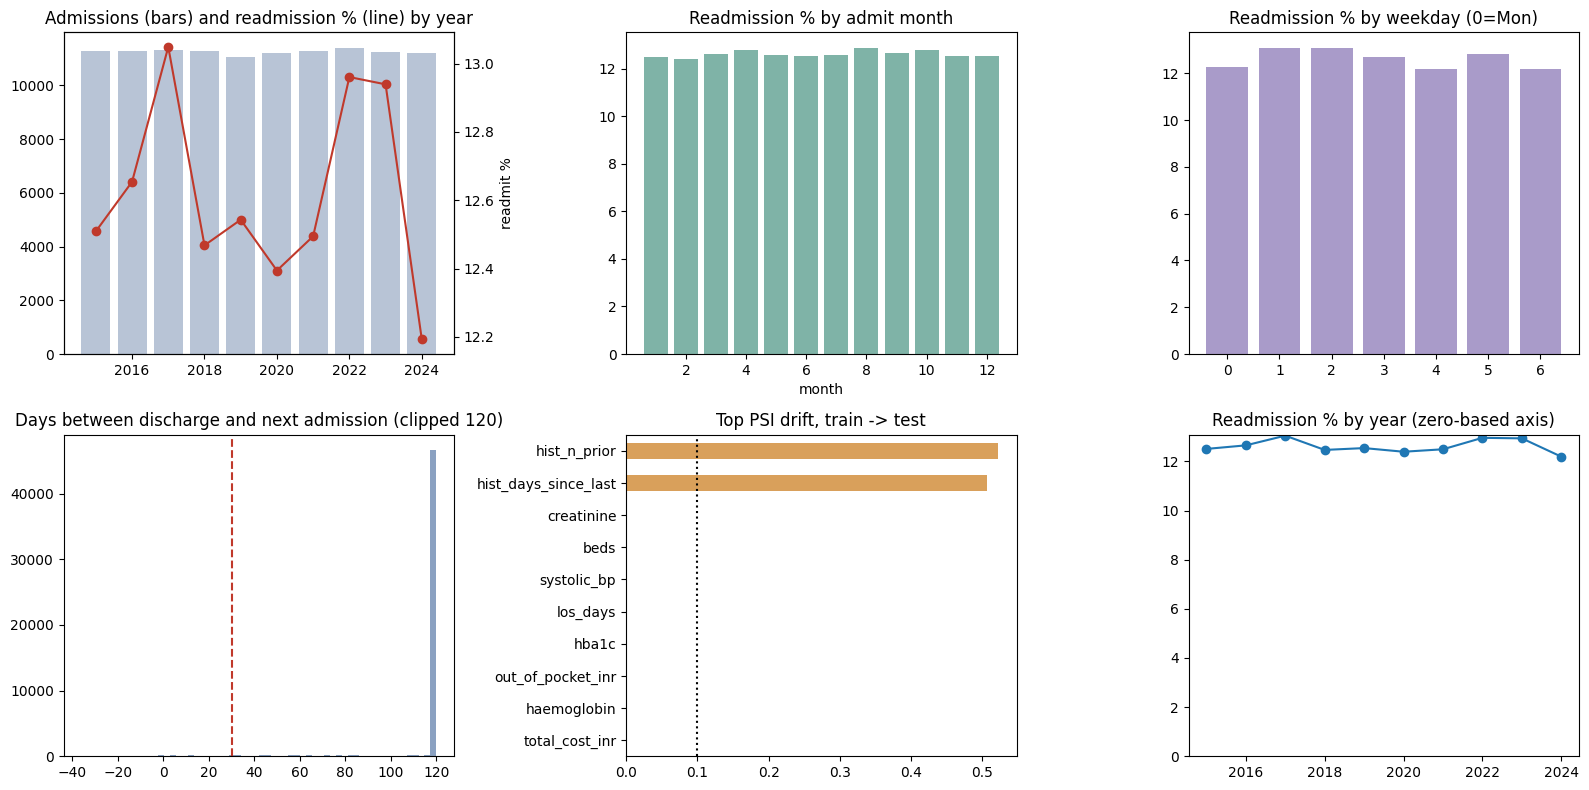

In [5]:
def psi(a, b, bins=10):
    a = a[~np.isnan(a)]; b = b[~np.isnan(b)]
    edges = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3: return 0.0
    edges[0], edges[-1] = -np.inf, np.inf
    pa = np.clip(np.histogram(a, edges)[0] / len(a), 1e-4, None); pb = np.clip(np.histogram(b, edges)[0] / len(b), 1e-4, None)
    return float(np.sum((pb - pa) * np.log(pb / pa)))

ytab = df.groupby('year').agg(admissions=('readmitted_30d', 'size'), rate=('readmitted_30d', 'mean'))
mtab = df.groupby('month').readmitted_30d.agg(['size', 'mean']); dtab = df.groupby('dow').readmitted_30d.agg(['size', 'mean'])
print('Yearly volume and readmission rate:'); print(ytab.round(4).to_string())

last = df.assign(ym=df.admit_date.dt.to_period('M')).groupby('ym').readmitted_30d.agg(['size', 'mean']).tail(6)
print('\nLast 6 months (a sharp drop in the final month would signal label censoring):'); print(last.round(4).to_string())

psi_tab = pd.Series({c: psi(df[c].values[tr].astype(float), df[c].values[te].astype(float)) for c in NUM}).sort_values(ascending=False)
print('\nFeature drift train -> test (PSI; >0.1 moderate, >0.25 major):'); print(psi_tab.head(8).round(4).to_string())

m = df.audit_next_gap.notna()
tab = pd.crosstab(df.readmitted_30d[m], (df.audit_next_gap[m] <= 30).map({True: 'next admit <=30d', False: 'next admit >30d'}))
print('\nLabel sanity check (rows that HAVE a later admission in this dataset):'); print(tab.to_string())
print(f'share of label=1 rows with a recorded next admission within 30d: {((df.audit_next_gap <= 30) & (y == 1)).sum() / max(y.sum(), 1):.3f}')

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
ax[0, 0].bar(ytab.index, ytab.admissions, color='#b8c4d6'); a2 = ax[0, 0].twinx(); a2.plot(ytab.index, ytab.rate * 100, 'o-', color='#c0392b')
ax[0, 0].set_title('Admissions (bars) and readmission % (line) by year'); a2.set_ylabel('readmit %')
ax[0, 1].bar(mtab.index, mtab['mean'] * 100, color='#7fb3a7'); ax[0, 1].set_title('Readmission % by admit month'); ax[0, 1].set_xlabel('month')
ax[0, 2].bar(dtab.index, dtab['mean'] * 100, color='#a99bc9'); ax[0, 2].set_title('Readmission % by weekday (0=Mon)')
gaps = df.audit_next_gap.dropna(); ax[1, 0].hist(gaps.clip(upper=120), bins=60, color='#8aa1c1'); ax[1, 0].axvline(30, color='#c0392b', ls='--')
ax[1, 0].set_title('Days between discharge and next admission (clipped 120)')
psi_tab.head(10)[::-1].plot.barh(ax=ax[1, 1], color='#d9a05b'); ax[1, 1].axvline(0.1, color='k', ls=':'); ax[1, 1].set_title('Top PSI drift, train -> test')
ax[1, 2].plot(ytab.index, ytab.rate * 100, 'o-'); ax[1, 2].set_ylim(0, None); ax[1, 2].set_title('Readmission % by year (zero-based axis)')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'time_analysis.png'), dpi=150); plt.show()

## 5. Clinical-note text (feature-grounded, no label)
`make_notes.py` content is inlined below so this notebook is standalone. Every sentence comes from structured fields known at discharge. **The notes carry the same information as the tabular features**, so retrieval over them is realistic in form but not a source of new signal. Say so in the write-up.

In [6]:
# ---- inlined make_notes.py (feature-grounded notes, no label) ----
"""
make_notes.py - feature-grounded synthetic discharge summaries.

Builds a realistic, varied discharge-summary paragraph for every admission using ONLY
information known at discharge (the structured fields). It never reads the label or any
post-discharge column, so it cannot leak the outcome.

HONEST CAVEAT (put this in your write-up): the notes are a re-expression of the structured
features. They add realistic text for the retrieval step, but no new predictive information,
so do not expect the RAG feature to beat the tabular models by much.

Usage (in your notebook, after building `df` one row per admission):
    from make_notes import add_notes
    df = add_notes(df, seed=42, style_noise=0.25)
    notes = df.note.tolist()
"""
import hashlib
import numpy as np
import pandas as pd

REQUIRED = [
    "admission_id", "age", "gender", "admit_type", "ward_type", "tier", "los_days",
    "dx_list", "charlson_index", "comorbidity_count", "hba1c", "creatinine", "haemoglobin",
    "systolic_bp", "num_procedures", "hist_n_prior", "hist_days_since_last",
    "insurance_type", "bpl_card", "total_cost_inr", "out_of_pocket_inr",
    "discharge_type", "patient_state", "hospital_state",
]
FORBIDDEN = {"readmitted_30d", "readmit_date", "days_to_readmit", "readmission_date"}


def _rng(key, seed):
    h = int(hashlib.md5(f"{seed}-{key}".encode()).hexdigest()[:8], 16)
    return np.random.default_rng(h)


def _pick(r, options):
    return options[int(r.integers(len(options)))]


def _i(v, default=0):
    return int(v) if pd.notna(v) else default


def _truthy(v):
    return str(v).strip().lower() in {"1", "y", "yes", "true", "t"}


def _lab_findings(row, r, keep):
    out = []

    def add(p, text):
        if r.random() < p:
            out.append(text)

    if pd.notna(row.hba1c):
        v = row.hba1c
        if v >= 8:
            add(1.0, _pick(r, [f"HbA1c {v:.1f}% indicating poorly controlled diabetes",
                               f"markedly raised HbA1c ({v:.1f}%)"]))
        elif v >= 6.5:
            add(keep, _pick(r, [f"HbA1c {v:.1f}% in the diabetic range",
                                f"HbA1c {v:.1f}%, diabetes under moderate control"]))
        else:
            add(keep * 0.4, f"HbA1c {v:.1f}% within target")
    if pd.notna(row.creatinine):
        v = row.creatinine
        if v > 1.3:
            add(1.0, _pick(r, [f"creatinine {v:.2f} mg/dL suggesting reduced renal function",
                               f"elevated creatinine ({v:.2f} mg/dL)"]))
        else:
            add(keep * 0.4, f"creatinine {v:.2f} mg/dL, renal function preserved")
    if pd.notna(row.haemoglobin):
        v = row.haemoglobin
        if v < 12:
            add(1.0, _pick(r, [f"haemoglobin {v:.1f} g/dL consistent with anaemia",
                               f"low haemoglobin ({v:.1f} g/dL)"]))
        else:
            add(keep * 0.4, f"haemoglobin {v:.1f} g/dL")
    if pd.notna(row.systolic_bp):
        v = row.systolic_bp
        if v >= 160:
            add(1.0, f"hypertensive at discharge review (systolic BP {v:.0f})")
        elif v < 90:
            add(1.0, f"hypotension noted (systolic BP {v:.0f})")
        else:
            add(keep * 0.5, f"systolic BP {v:.0f}")
    return out


def build_note(row, seed=42, style_noise=0.25):
    r = _rng(row.admission_id, seed)
    keep = 1.0 - style_noise  # chance of keeping optional, non-abnormal details

    sex = {"M": "male", "F": "female"}.get(str(row.gender), "patient")
    adm = str(row.admit_type).lower()
    ward = str(row.ward_type).upper() if len(str(row.ward_type)) <= 4 else str(row.ward_type).lower()
    opener = _pick(r, [
        f"{_i(row.age)}-year-old {sex} with {adm} admission to {ward} care at a {row.tier} hospital.",
        f"{_i(row.age)} y/o {sex}, {adm} admission, managed in the {ward} ward of a {row.tier} hospital.",
        f"This {_i(row.age)}-year-old {sex} was admitted ({adm}) to the {ward} ward of a {row.tier} hospital.",
    ])

    dxs = [d.strip() for d in str(row.dx_list).split(";") if d.strip()]
    if dxs:
        principal = f"Principal diagnosis: {dxs[0]}."
        secondary = (" Secondary: " + ", ".join(dxs[1:4]) + ".") if len(dxs) > 1 else ""
    else:
        principal, secondary = "Diagnosis not recorded.", ""

    course = _pick(r, [
        f"Length of stay {_i(row.los_days)} days",
        f"Hospital stay of {_i(row.los_days)} days",
    ])
    if row.los_days >= 7:
        course += _pick(r, [", a prolonged admission", ", longer than typical"])
    course += f", {_i(row.num_procedures)} procedure(s) performed."

    burden = (f"Charlson comorbidity index {_i(row.charlson_index)} with "
              f"{_i(row.comorbidity_count)} documented comorbidities.")
    if row.charlson_index >= 4:
        burden += " High comorbidity burden."

    labs = _lab_findings(row, r, keep)
    labs_txt = ("Key findings: " + "; ".join(labs) + ".") if labs else ""

    if _i(row.hist_n_prior) == 0 or pd.isna(row.hist_days_since_last):
        hist = "First recorded admission in this system."
    else:
        hist = f"{_i(row.hist_n_prior)} earlier admission(s) on record; last discharge {_i(row.hist_days_since_last)} days before this admission."
        if row.hist_days_since_last <= 30:
            hist += " Admission follows a recent discharge."

    social = []
    if r.random() < max(keep, 0.6):
        social.append(f"Insurance: {row.insurance_type}")
    if _truthy(row.bpl_card):
        social.append("holds a below-poverty-line card")
    if pd.notna(row.total_cost_inr) and row.total_cost_inr > 0 and pd.notna(row.out_of_pocket_inr):
        share = row.out_of_pocket_inr / row.total_cost_inr
        if share >= 0.5:
            social.append(f"high out-of-pocket burden ({share:.0%} of the bill)")
    if str(row.patient_state) != str(row.hospital_state):
        social.append("travelled from another state for care")
    social_txt = ("Social and financial context: " + "; ".join(social) + ".") if social else ""

    dc = str(row.discharge_type)
    if dc.upper() == "LAMA":
        disp = "Discharged against medical advice (LAMA)."
    elif dc.lower() == "recovered":
        disp = _pick(r, ["Discharged recovered.", "Discharged in recovered condition."])
    else:
        disp = f"Discharge disposition: {dc}."

    parts = [opener, principal + secondary, course, burden, labs_txt, hist, social_txt, disp]
    return " ".join(p for p in parts if p)


def add_notes(df, seed=42, style_noise=0.25):
    """Return df with a `note` column. Raises if a label-like column is used or required columns are missing."""
    missing = [c for c in REQUIRED if c not in df.columns]
    assert not missing, f"missing columns: {missing}"
    assert not (set(REQUIRED) & FORBIDDEN), "label-like column in REQUIRED"
    df = df.copy()
    df["dx_list"] = df["dx_list"].fillna("")
    df["note"] = [build_note(row, seed, style_noise) for row in df[REQUIRED].itertuples(index=False)]
    return df


In [7]:
import sys
# Safeguard and redefine the helper functions to prevent global namespace overriding
def _i(v, default=0):
    return int(v) if pd.notna(v) else default

def _pick(r, options):
    return options[int(r.integers(len(options)))]

# Re-bind them to the module or global namespace so build_note can access them correctly
globals()['_i'] = _i
globals()['_pick'] = _pick

df = add_notes(df, seed=CFG['SEED'], style_noise=CFG['STYLE_NOISE'])
notes = df.note.tolist()
assert not any('readmi' in n.lower() for n in notes), 'note text mentions readmission'
print(df.note.iloc[0]); print()
print(df.note.iloc[len(df) // 2])
print('\nmean note length (words):', round(df.note.str.split().str.len().mean(), 1))

25 y/o female, elective admission, managed in the HDU ward of a tier3 hospital. Principal diagnosis: Alcoholic liver disease. Secondary: Urinary tract infection. Length of stay 9 days, longer than typical, 2 procedure(s) performed. Charlson comorbidity index 2 with 1 documented comorbidities. Key findings: HbA1c 6.7% in the diabetic range; systolic BP 104. First recorded admission in this system. Social and financial context: Insurance: Private; travelled from another state for care. Discharged recovered.

This 38-year-old male was admitted (elective) to the general ward of a tier3 hospital. Principal diagnosis: Malignant neoplasm — colon. Hospital stay of 14 days, a prolonged admission, 0 procedure(s) performed. Charlson comorbidity index 2 with 0 documented comorbidities. Key findings: haemoglobin 13.8 g/dL; systolic BP 146. 1 earlier admission(s) on record; last discharge 185 days before this admission. Social and financial context: Insurance: ESI; travelled from another state for c

## 6. Baselines and rolling-origin validation
Any model must beat trivial baselines. The rolling-origin check trains on all earlier years and tests on the next year, showing whether performance is stable over time (not just on one lucky split).

                  baseline  test_AUC  test_PR_AUC
     prior only (constant)    0.5000       0.1257
history features only (LR)    0.6216       0.1982
all tabular (LR, balanced)    0.7543       0.3571

Rolling-origin (train on all earlier years, test on the next year), LR balanced:
 test_year  n_train  n_test  base_rate    AUC  PR_AUC
      2018    33908   11277     0.1247 0.7560  0.3547
      2019    45185   11074     0.1254 0.7460  0.3491
      2020    56259   11223     0.1239 0.7558  0.3533
      2021    67482   11269     0.1249 0.7543  0.3591
      2022    78751   11404     0.1296 0.7380  0.3445
      2023    90155   11245     0.1294 0.7598  0.3716
      2024   101400   11187     0.1219 0.7493  0.3429


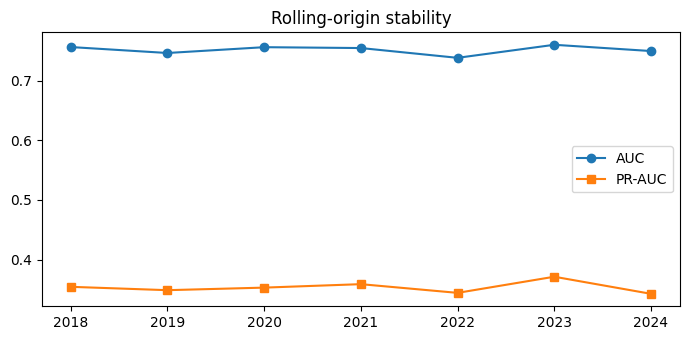

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve, f1_score,
                             precision_score, recall_score, roc_curve, brier_score_loss)

def make_pre(num, cat, scale):
    nt = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler() if scale else 'passthrough')])
    return ColumnTransformer([('num', nt, num), ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50, sparse_output=False), cat)])

X_base = df[NUM + CAT].copy()
HIST = ['hist_n_prior', 'hist_days_since_last', 'hist_has_prior', 'prev_admissions']

def quick_lr(num, cat, tr_i, te_i, C=0.1):
    p = Pipeline([('pre', make_pre(num, cat, True)), ('clf', LogisticRegression(C=C, max_iter=2000, class_weight='balanced'))])
    p.fit(X_base.iloc[tr_i], y[tr_i]); return p.predict_proba(X_base.iloc[te_i])[:, 1]

p_hist, p_all = quick_lr(HIST, [], tr, te), quick_lr(NUM, CAT, tr, te)
base_rows = [dict(baseline='prior only (constant)', test_AUC=0.5, test_PR_AUC=y[te].mean()),
             dict(baseline='history features only (LR)', test_AUC=roc_auc_score(y[te], p_hist), test_PR_AUC=average_precision_score(y[te], p_hist)),
             dict(baseline='all tabular (LR, balanced)', test_AUC=roc_auc_score(y[te], p_all), test_PR_AUC=average_precision_score(y[te], p_all))]
print(pd.DataFrame(base_rows).round(4).to_string(index=False))

years = sorted(set(yr)); folds = [v for v in years if v >= years[0] + 3]
ro = []
for vy in folds:
    a, b = np.where(yr < vy)[0], np.where(yr == vy)[0]
    p = quick_lr(NUM, CAT, a, b); ro.append(dict(test_year=vy, n_train=len(a), n_test=len(b), base_rate=y[b].mean(),
                                                  AUC=roc_auc_score(y[b], p), PR_AUC=average_precision_score(y[b], p)))
RO = pd.DataFrame(ro); print('\nRolling-origin (train on all earlier years, test on the next year), LR balanced:'); print(RO.round(4).to_string(index=False))
plt.figure(figsize=(7, 3.5)); plt.plot(RO.test_year, RO.AUC, 'o-', label='AUC'); plt.plot(RO.test_year, RO.PR_AUC, 's-', label='PR-AUC')
plt.legend(); plt.title('Rolling-origin stability'); plt.tight_layout(); plt.savefig(os.path.join(OUT, 'rolling_origin.png'), dpi=150); plt.show()

## 7. Note embeddings

In [9]:
def embed_notes(texts):
    tag = CFG['EMBED_BACKEND'] + '_' + CFG['EMBED_MODEL'].split('/')[-1] + f'_{len(texts)}_n{CFG["STYLE_NOISE"]}'
    cache = os.path.join(OUT, f'emb_{tag}.npy')
    if os.path.exists(cache): return np.load(cache)
    if CFG['EMBED_BACKEND'] == 'sbert':
        from sentence_transformers import SentenceTransformer
        E = SentenceTransformer(CFG['EMBED_MODEL']).encode(texts, batch_size=256, show_progress_bar=True,
                                                           normalize_embeddings=True, convert_to_numpy=True)
    else:   # TF-IDF + SVD (unsupervised, no labels used)
        from sklearn.feature_extraction.text import TfidfVectorizer
        from sklearn.decomposition import TruncatedSVD
        from sklearn.preprocessing import normalize
        Xt = TfidfVectorizer(min_df=5, ngram_range=(1, 2), max_features=50000).fit_transform(texts)
        E = normalize(TruncatedSVD(128, random_state=CFG['SEED']).fit_transform(Xt))
    E = E.astype(np.float32); np.save(cache, E); return E

t0 = time.time(); E = embed_notes(notes); print('embeddings', E.shape, f'{time.time() - t0:.0f}s')

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/440 [00:00<?, ?it/s]

embeddings (112587, 384) 246s


## 8. RAG retrieval with a time-aware, leakage-safe corpus
For query admission *q*, corpus admission *c* is eligible only if `discharge_c + 30d < admit_q` (its label was observable) and `patient_c != patient_q`. The corpus is train + val (never test) and keeps its **natural prevalence**; balancing is applied later, at model-fit time only.

In [10]:
admit_day = df.admit_date.values.astype('datetime64[D]').astype(np.int64)
disch_day = df.discharge_date.values.astype('datetime64[D]').astype(np.int64)
pid = pd.factorize(df.patient_id)[0]
corpus_idx = np.concatenate([tr, va]); assert not np.isin(te, corpus_idx).any(), 'test rows must never be in the corpus'

def retrieve(E, corpus_idx, query_idx, kmax, chunk=512):
    C = E[corpus_idx]; c_ready = disch_day[corpus_idx] + CFG['LABEL_LAG_DAYS']; c_pid = pid[corpus_idx]
    kmax = min(kmax, len(corpus_idx))
    nbr = np.full((len(query_idx), kmax), -1, dtype=np.int64); sim_out = np.full((len(query_idx), kmax), np.nan, dtype=np.float32)
    for s in range(0, len(query_idx), chunk):
        q = query_idx[s:s + chunk]; sim = E[q] @ C.T
        elig = c_ready[None, :] < admit_day[q][:, None]
        if CFG['EXCLUDE_SAME_PATIENT']: elig &= c_pid[None, :] != pid[q][:, None]
        sim[~elig] = -np.inf
        part = np.argpartition(-sim, kmax - 1, axis=1)[:, :kmax]; ps = np.take_along_axis(sim, part, 1)
        order = np.argsort(-ps, axis=1); part = np.take_along_axis(part, order, 1); ps = np.take_along_axis(ps, order, 1)
        ok = np.isfinite(ps); nbr[s:s + len(q)] = np.where(ok, corpus_idx[part], -1); sim_out[s:s + len(q)] = np.where(ok, ps, np.nan)
    return nbr, sim_out

def rag_features(nbr, sim, k):
    nb, sm = nbr[:, :k], sim[:, :k]; valid = nb >= 0
    lab = np.where(valid, y[np.where(valid, nb, 0)], 0).astype(float); n = valid.sum(1)
    rate = (lab.sum(1) + CFG['SMOOTH_M'] * prior) / (n + CFG['SMOOTH_M'])
    w = np.where(valid, np.clip(np.nan_to_num(sm), 0, None), 0.0)
    wrate = np.where(w.sum(1) > 0, (w * lab).sum(1) / np.maximum(w.sum(1), 1e-9), prior)
    sim_mean = np.where(n > 0, np.where(valid, np.nan_to_num(sm), 0).sum(1) / np.maximum(n, 1), 0.0)
    return pd.DataFrame(dict(rag_rate=rate, rag_wrate=wrate, rag_sim_mean=sim_mean, rag_n_frac=n / k))

def leakage_check(nbr, n=2000):
    rng = np.random.default_rng(0)
    for r in rng.choice(len(nbr), min(n, len(nbr)), replace=False):
        nb = nbr[r][nbr[r] >= 0]
        assert r not in nb, 'row retrieved itself'
        assert (disch_day[nb] + CFG['LABEL_LAG_DAYS'] < admit_day[r]).all(), 'neighbour label not yet known'
        if CFG['EXCLUDE_SAME_PATIENT']: assert (pid[nb] != pid[r]).all(), 'same-patient neighbour'
    print('leakage self-check passed')

t0 = time.time(); NBR, SIM = retrieve(E, corpus_idx, np.arange(len(df)), max(CFG['K_GRID'])); print(f'retrieval {time.time() - t0:.0f}s')
leakage_check(NBR)

retrieval 210s
leakage self-check passed


## 9. Choose k
Selecting k by LR+RAG validation AUC was uninformative in the earlier runs (identical for every k). Here we also report the **RAG-only** validation AUC and the spread of the feature, which separate the options properly. k is chosen on RAG-only validation AUC.

In [11]:
rows = []
for k in CFG['K_GRID']:
    R = rag_features(NBR, SIM, k); Xk = pd.concat([X_base, R], axis=1)
    p = Pipeline([('pre', make_pre(NUM + RAG_COLS, CAT, True)), ('clf', LogisticRegression(C=0.1, max_iter=2000, class_weight='balanced'))])
    p.fit(Xk.iloc[tr], y[tr])
    rows.append(dict(k=k, LR_plus_RAG_val_AUC=roc_auc_score(y[va], p.predict_proba(Xk.iloc[va])[:, 1]),
                     RAG_only_val_AUC=roc_auc_score(y[va], R.rag_rate.values[va]), rag_rate_std=R.rag_rate.values[va].std()))
KT = pd.DataFrame(rows); print(KT.round(5).to_string(index=False))
BEST_K = int(KT.sort_values('RAG_only_val_AUC', ascending=False).iloc[0].k); CFG['BEST_K'] = BEST_K; print('chosen k =', BEST_K)
RAG_DF = rag_features(NBR, SIM, BEST_K); X_rag = pd.concat([X_base, RAG_DF], axis=1)
print('RAG feature alone: val AUC', round(roc_auc_score(y[va], RAG_DF.rag_rate.values[va]), 4), '| test AUC', round(roc_auc_score(y[te], RAG_DF.rag_rate.values[te]), 4))

  k  LR_plus_RAG_val_AUC  RAG_only_val_AUC  rag_rate_std
  5              0.73795           0.60632       0.07814
 10              0.73792           0.63215       0.08228
 25              0.73793           0.66458       0.08032
 50              0.73800           0.68269       0.07664
100              0.73811           0.69138       0.07267
chosen k = 100
RAG feature alone: val AUC 0.6914 | test AUC 0.7011


## 10. Evaluation helpers

In [12]:
def pick_threshold(yt, p):
    pr, rc, th = precision_recall_curve(yt, p); f1 = 2 * pr * rc / np.clip(pr + rc, 1e-12, None)
    return th[np.nanargmax(f1[:-1])]

def metrics(yt, p, thr):
    pred = (p >= thr).astype(int)
    return dict(AUC_ROC=roc_auc_score(yt, p), PR_AUC=average_precision_score(yt, p), F1=f1_score(yt, pred),
                Precision=precision_score(yt, pred, zero_division=0), Recall=recall_score(yt, pred), Threshold=thr)

RESULTS, PRED, MODELS = [], {}, {}
def record(model, rag, seed, p_va, p_te, strategy):
    thr = pick_threshold(y[va], p_va); m = metrics(y[te], p_te, thr); m.update(model=model, rag=rag, seed=seed, balance=strategy)
    RESULTS.append(m); PRED.setdefault((model, rag), (p_va, p_te))
    print(f"{model:18s} rag={int(rag)} seed={seed}  AUC={m['AUC_ROC']:.4f}  PR-AUC={m['PR_AUC']:.4f}  F1={m['F1']:.4f}  P={m['Precision']:.3f}  R={m['Recall']:.3f}")

## 11. Balanced-data study (training rows only)
Four strategies for the 1:7 class imbalance: **none**, **class weights**, **random under-sampling** to 1:1, **random over-sampling** to 1:1. Only the rows used to *fit* change. Validation, test, and the retrieval corpus keep the natural prevalence. Balancing mostly shifts probabilities (so thresholds must be re-tuned on validation, which we do) and can change recall/precision, but ranking metrics move little; calibration is repaired afterwards.

In [13]:
def rows_for(strategy, idx, seed):
    idx = np.asarray(idx); pos, neg = idx[y[idx] == 1], idx[y[idx] == 0]; rng = np.random.default_rng(seed)
    if strategy == 'undersample': return rng.permutation(np.concatenate([pos, rng.choice(neg, len(pos), replace=False)]))
    if strategy == 'oversample':  return rng.permutation(np.concatenate([neg, rng.choice(pos, len(neg), replace=True)]))
    return idx

def fit_model(name, strategy, num, cat, X, seed=42, C=0.1, trees=None):
    fit_idx = rows_for(strategy, tr, seed); cw = strategy == 'class_weight'
    if name == 'LogReg':
        clf, scale = LogisticRegression(C=C, max_iter=3000, class_weight='balanced' if cw else None), True
    else:
        clf, scale = RandomForestClassifier(n_estimators=trees or CFG['RF_TREES'], min_samples_leaf=CFG['RF_MIN_LEAF'], max_features='sqrt',
                                            n_jobs=-1, random_state=seed, class_weight='balanced_subsample' if cw else None), False
    pipe = Pipeline([('pre', make_pre(num, cat, scale)), ('clf', clf)]); pipe.fit(X.iloc[fit_idx], y[fit_idx]); return pipe

study = []
for strat in CFG['BALANCE_GRID']:
    for name in ['LogReg', 'RandomForest']:
        m = fit_model(name, strat, NUM + RAG_COLS, CAT, X_rag, trees=CFG['RF_STUDY_TREES'])
        pv, pt = m.predict_proba(X_rag.iloc[va])[:, 1], m.predict_proba(X_rag.iloc[te])[:, 1]; thr = pick_threshold(y[va], pv)
        study.append(dict(balance=strat, model=name, n_fit=len(rows_for(strat, tr, 42)), val_AUC=roc_auc_score(y[va], pv),
                          val_PR_AUC=average_precision_score(y[va], pv), **metrics(y[te], pt, thr), Brier_raw=brier_score_loss(y[te], pt)))
S = pd.DataFrame(study); print(S.drop(columns='Threshold').round(4).to_string(index=False))
avg = S.groupby('balance').val_PR_AUC.mean(); best = avg.idxmax()
BAL = 'class_weight' if ('class_weight' in avg.index and avg[best] - avg['class_weight'] < 0.002) else best
print('\nmean validation PR-AUC by strategy:'); print(avg.round(4).to_string()); print('\nchosen balancing strategy =', BAL, '(ties within 0.002 go to class_weight: simplest, no data discarded)')
S.to_csv(os.path.join(OUT, 'balancing_study.csv'), index=False)

     balance        model  n_fit  val_AUC  val_PR_AUC  AUC_ROC  PR_AUC     F1  Precision  Recall  Brier_raw
        none       LogReg  78751   0.7382      0.3453   0.7546  0.3572 0.3842     0.3248  0.4704     0.0961
        none RandomForest  78751   0.7330      0.3282   0.7470  0.3339 0.3745     0.3184  0.4548     0.0976
class_weight       LogReg  78751   0.7381      0.3450   0.7543  0.3567 0.3846     0.3201  0.4817     0.1933
class_weight RandomForest  78751   0.7314      0.3241   0.7473  0.3313 0.3751     0.2795  0.5701     0.1656
 undersample       LogReg  19826   0.7370      0.3436   0.7540  0.3568 0.3851     0.3243  0.4739     0.1919
 undersample RandomForest  19826   0.7306      0.3216   0.7475  0.3302 0.3755     0.3130  0.4690     0.2007
  oversample       LogReg 137676   0.7380      0.3452   0.7539  0.3560 0.3828     0.3171  0.4828     0.1930
  oversample RandomForest 137676   0.7303      0.3258   0.7475  0.3345 0.3718     0.2751  0.5733     0.1660

mean validation PR-AUC by s

## 12. Final Logistic Regression and Random Forest (with / without RAG), chosen balancing

In [14]:
def run_classic(name, use_rag, seed):
    X = X_rag if use_rag else X_base; num = NUM + (RAG_COLS if use_rag else [])
    if name == 'LogReg':
        best = None
        for C in CFG['LR_C_GRID']:
            m = fit_model('LogReg', BAL, num, CAT, X, seed, C=C); a = roc_auc_score(y[va], m.predict_proba(X.iloc[va])[:, 1])
            if best is None or a > best[0]: best = (a, m)
        m = best[1]
    else:
        m = fit_model('RandomForest', BAL, num, CAT, X, seed)
    MODELS.setdefault((name, use_rag), m)
    record(name, use_rag, seed, m.predict_proba(X.iloc[va])[:, 1], m.predict_proba(X.iloc[te])[:, 1], BAL)

for use_rag in [False, True]:
    run_classic('LogReg', use_rag, 0)
    for s in CFG['SEEDS']: run_classic('RandomForest', use_rag, s)

LogReg             rag=0 seed=0  AUC=0.7545  PR-AUC=0.3575  F1=0.3855  P=0.324  R=0.475
RandomForest       rag=0 seed=42  AUC=0.7498  PR-AUC=0.3389  F1=0.3794  P=0.306  R=0.499
RandomForest       rag=0 seed=43  AUC=0.7496  PR-AUC=0.3371  F1=0.3771  P=0.318  R=0.464
RandomForest       rag=0 seed=44  AUC=0.7498  PR-AUC=0.3393  F1=0.3767  P=0.312  R=0.476
LogReg             rag=1 seed=0  AUC=0.7546  PR-AUC=0.3572  F1=0.3845  P=0.326  R=0.470
RandomForest       rag=1 seed=42  AUC=0.7482  PR-AUC=0.3354  F1=0.3751  P=0.282  R=0.559
RandomForest       rag=1 seed=43  AUC=0.7490  PR-AUC=0.3346  F1=0.3774  P=0.284  R=0.560
RandomForest       rag=1 seed=44  AUC=0.7488  PR-AUC=0.3340  F1=0.3787  P=0.304  R=0.501


## 13. Fine-tuned Transformer (note text + scaled tabular features; RAG scalars concatenated to the pooled embedding)
Uses the chosen balancing strategy: under-sampling trains on a 1:1 subset (about 4x faster), class weights use a positive-class loss weight, otherwise plain BCE. Skipped automatically without a GPU unless `ALLOW_CPU_TRANSFORMER=True`.

In [15]:
TAB, IDS, IDS_MODEL = None, None, None

def run_transformer(use_rag, seed, hybrid=True):
    import torch, torch.nn as nn
    from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
    global TAB, IDS, IDS_MODEL
    dev = 'cuda' if torch.cuda.is_available() else 'cpu'
    if dev == 'cpu' and not CFG['ALLOW_CPU_TRANSFORMER']:
        print('No GPU: skipping the Transformer (enable a T4 runtime, or set ALLOW_CPU_TRANSFORMER=True)'); return
    tf_name = 'Transformer' + ('+Tab' if hybrid else '') + f"[{CFG['TF_MODEL'].split('/')[-1]}]"
    set_seed(seed)
    if hybrid and TAB is None: TAB = make_pre(NUM, CAT, True).fit(X_base.iloc[tr]).transform(X_base).astype(np.float32)
    tok = AutoTokenizer.from_pretrained(CFG['TF_MODEL'])
    if IDS is None or IDS_MODEL != CFG['TF_MODEL']:
        IDS = tok(notes, truncation=True, max_length=CFG['TF_MAX_LEN'])['input_ids']; IDS_MODEL = CFG['TF_MODEL']
    parts = []
    if use_rag:
        r = RAG_DF[RAG_COLS].values.astype(np.float32); parts.append((r - r[tr].mean(0)) / (r[tr].std(0) + 1e-6))
    if hybrid: parts.append(TAB)
    extra = np.concatenate(parts, 1).astype(np.float32) if parts else None; use_extra = extra is not None

    tf_strat = BAL if BAL in ('undersample', 'class_weight') else ('class_weight' if BAL == 'oversample' else 'none')
    tr_i = rows_for('undersample' if tf_strat == 'undersample' else 'none', tr, seed)
    sub = CFG['TF_TRAIN_SUBSAMPLE']
    if sub and sub < len(tr_i): tr_i = np.random.default_rng(seed).choice(tr_i, sub, replace=False)
    epochs = CFG['TF_EPOCHS'] if dev == 'cuda' else 1

    class Net(nn.Module):
        def __init__(s, n_extra):
            super().__init__(); s.enc = AutoModel.from_pretrained(CFG['TF_MODEL']); h = s.enc.config.hidden_size
            s.proj = nn.Sequential(nn.Linear(n_extra, 64), nn.ReLU()) if n_extra > 8 else None
            d = 64 if s.proj is not None else n_extra
            s.drop = nn.Dropout(0.1); s.head = nn.Linear(h + d, 1)
        def forward(s, x, m, e=None):
            o = s.enc(input_ids=x, attention_mask=m).last_hidden_state
            mm = m.unsqueeze(-1).to(o.dtype); pooled = (o * mm).sum(1) / mm.sum(1).clamp(min=1)
            if e is not None:
                e = s.proj(e.to(pooled.dtype)).to(pooled.dtype) if s.proj is not None else e.to(pooled.dtype)
                pooled = torch.cat([pooled, e], 1)
            return s.head(s.drop(pooled)).squeeze(-1)

    def batches(idx, bs, shuffle):
        idx = np.array(idx)
        if shuffle: idx = np.random.permutation(idx)
        for s in range(0, len(idx), bs):
            b = idx[s:s + bs]; enc = tok.pad({'input_ids': [IDS[i] for i in b]}, return_tensors='pt')
            e = torch.from_numpy(extra[b]).to(dev) if use_extra else None
            yield b, enc['input_ids'].to(dev), enc['attention_mask'].to(dev), e

    @torch.no_grad()
    def predict(idx):
        net.eval(); out = []
        for b, x, m, e in batches(idx, 256, False):
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(dev == 'cuda')):
                out.append(torch.sigmoid(net(x, m, e).float()).cpu().numpy())
        return np.concatenate(out)

    net = Net(extra.shape[1] if use_extra else 0).to(dev)
    pos_w = torch.tensor(float((1 - y[tr_i].mean()) / y[tr_i].mean()), dtype=torch.float32, device=dev)
    lossf = nn.BCEWithLogitsLoss(pos_weight=pos_w) if tf_strat == 'class_weight' else nn.BCEWithLogitsLoss()
    opt = torch.optim.AdamW(net.parameters(), lr=CFG['TF_LR'], weight_decay=0.01)
    steps = epochs * int(np.ceil(len(tr_i) / CFG['TF_BS'])); sch = get_linear_schedule_with_warmup(opt, int(0.06 * steps), steps)
    scaler = torch.amp.GradScaler('cuda', enabled=(dev == 'cuda')) if hasattr(torch.amp, 'GradScaler') else torch.cuda.amp.GradScaler(enabled=(dev == 'cuda'))
    best_auc, best_state = -1, None
    for ep in range(epochs):
        net.train(); t0 = time.time(); tot = 0
        for b, x, m, e in batches(tr_i, CFG['TF_BS'], True):
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(dev == 'cuda')):
                logit = net(x, m, e)
            loss = lossf(logit.float(), torch.from_numpy(y[b]).float().to(dev))
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(net.parameters(), 1.0); scaler.step(opt); scaler.update(); sch.step(); tot += loss.item() * len(b)
        pv = predict(va); a = roc_auc_score(y[va], pv)
        print(f'  [{tf_name} rag={int(use_rag)} seed={seed}] epoch {ep + 1}/{epochs} loss={tot / len(tr_i):.4f} val AUC={a:.4f} ({time.time() - t0:.0f}s)')
        if a > best_auc: best_auc, best_state = a, {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
    net.load_state_dict(best_state)
    record(tf_name, use_rag, seed, predict(va), predict(te), tf_strat)
    del net, opt
    if dev == 'cuda': torch.cuda.empty_cache()

if CFG['RUN_TRANSFORMER']:
    for use_rag in [False, True]:
        for s in CFG['TF_SEEDS']: run_transformer(use_rag, s, hybrid=True)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

...

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [Transformer+Tab[distilbert-base-uncased] rag=1 seed=43] epoch 1/2 loss=0.3446 val AUC=0.7310 (361s)
  [Transformer+Tab[distilbert-base-uncased] rag=1 seed=43] epoch 2/2 loss=0.3308 val AUC=0.7329 (361s)
Transformer+Tab[distilbert-base-uncased] rag=1 seed=43  AUC=0.7486  PR-AUC=0.3365  F1=0.3821  P=0.300  R=0.526


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  [Transformer+Tab[distilbert-base-uncased] rag=1 seed=44] epoch 1/2 loss=0.3467 val AUC=0.7314 (361s)
  [Transformer+Tab[distilbert-base-uncased] rag=1 seed=44] epoch 2/2 loss=0.3311 val AUC=0.7351 (360s)
Transformer+Tab[distilbert-base-uncased] rag=1 seed=44  AUC=0.7477  PR-AUC=0.3371  F1=0.3782  P=0.292  R=0.536


## 14. Results table, patient-cluster bootstrap, ROC and PR curves

                                               AUC_ROC          PR_AUC              F1         Precision          Recall        
                                                  mean     std    mean     std    mean     std      mean     std    mean     std
model                                    rag                                                                                    
LogReg                                   False  0.7545     NaN  0.3575     NaN  0.3855     NaN    0.3244     NaN  0.4750     NaN
                                         True   0.7546     NaN  0.3572     NaN  0.3845     NaN    0.3255     NaN  0.4697     NaN
RandomForest                             False  0.7497  0.0001  0.3385  0.0012  0.3777  0.0015    0.3118  0.0057  0.4795  0.0177
                                         True   0.7487  0.0004  0.3346  0.0007  0.3771  0.0019    0.2903  0.0122  0.5403  0.0338
Transformer+Tab[distilbert-base-uncased] False  0.7483  0.0009  0.3388  0.0003  0.3792  0.0020   

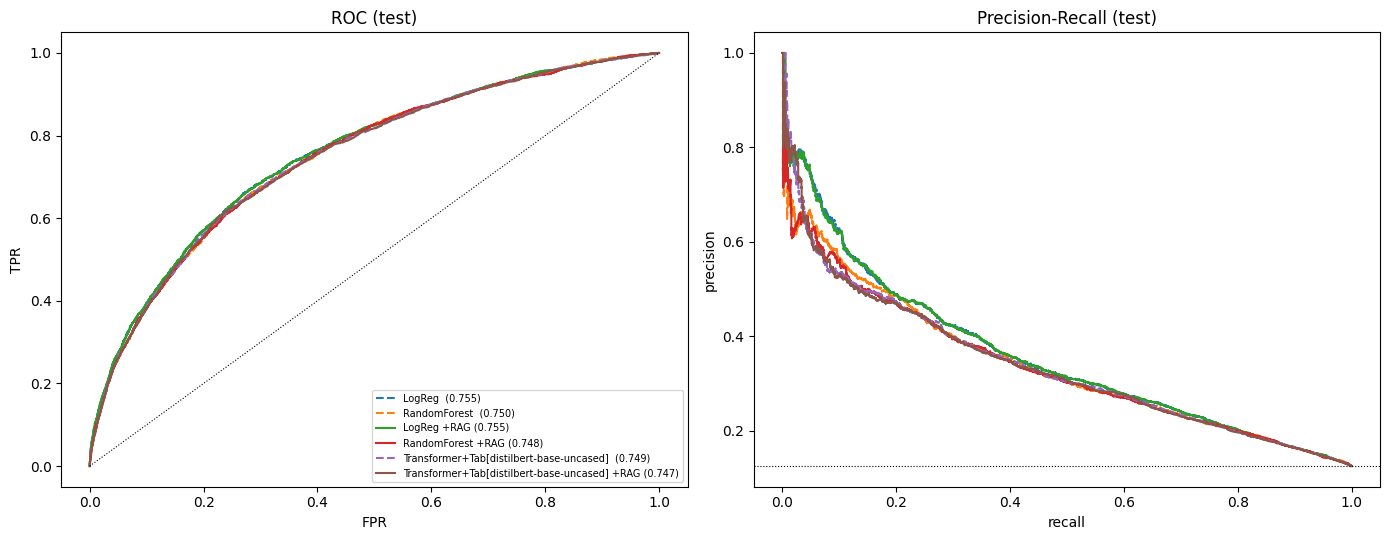

In [16]:
RES = pd.DataFrame(RESULTS); RES.to_csv(os.path.join(OUT, 'results_raw.csv'), index=False)
metric_cols = ['AUC_ROC', 'PR_AUC', 'F1', 'Precision', 'Recall']
SUM = RES.groupby(['model', 'rag'])[metric_cols].agg(['mean', 'std']).round(4)
print(SUM.to_string()); SUM.to_csv(os.path.join(OUT, 'results_summary.csv'))

pid_te = pid[te]; groups = {p: np.where(pid_te == p)[0] for p in np.unique(pid_te)}; keys = np.array(list(groups))
rng = np.random.default_rng(1); boots = [np.concatenate([groups[k] for k in rng.choice(keys, len(keys))]) for _ in range(CFG['N_BOOT'])]
rows = []
for name in sorted({k[0] for k in PRED}):
    if (name, False) not in PRED or (name, True) not in PRED: continue
    p0, p1 = PRED[(name, False)][1], PRED[(name, True)][1]; d = []
    for idx in boots:
        if y[te][idx].min() == y[te][idx].max(): continue
        d.append(roc_auc_score(y[te][idx], p1[idx]) - roc_auc_score(y[te][idx], p0[idx]))
    lo, hi = np.percentile(d, [2.5, 97.5]); rows.append(dict(model=name, mean_delta_AUC=np.mean(d), ci_low=lo, ci_high=hi, significant=bool(lo > 0 or hi < 0)))
print('\nEffect of the RAG feature on test AUC (paired patient-cluster bootstrap, 95% CI):'); print(pd.DataFrame(rows).round(5).to_string(index=False))
pd.DataFrame(rows).to_csv(os.path.join(OUT, 'rag_effect.csv'), index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5)); yt = y[te]
for (name, rag), (pv, pt) in PRED.items():
    f, t, _ = roc_curve(yt, pt); ax[0].plot(f, t, label=f'{name} {"+RAG" if rag else ""} ({roc_auc_score(yt, pt):.3f})', ls='-' if rag else '--')
    pr, rc, _ = precision_recall_curve(yt, pt); ax[1].plot(rc, pr, label=f'{name} {"+RAG" if rag else ""}', ls='-' if rag else '--')
ax[0].plot([0, 1], [0, 1], 'k:', lw=.8); ax[0].set_title('ROC (test)'); ax[0].legend(fontsize=7); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR')
ax[1].axhline(yt.mean(), color='k', ls=':', lw=.8); ax[1].set_title('Precision-Recall (test)'); ax[1].set_xlabel('recall'); ax[1].set_ylabel('precision')
plt.tight_layout(); plt.savefig(os.path.join(OUT, 'curves.png'), dpi=150); plt.show()

## 15. Operating points, calibration and risk bands (best model by validation AUC)
Balancing inflates raw probabilities, so we recalibrate with isotonic regression fitted on validation. Risk bands (high = top 10%, medium = next 20%) give the app something a care team can act on.

best by validation AUC: ('LogReg', True)
Brier raw 0.0961 -> calibrated 0.0964 (no-skill 0.1099)

Risk bands on the test set:
        patients  readmit_rate  readmits  share_of_all_readmits
band                                                           
high        2263         0.406       919                  0.326
medium      4390         0.196       861                  0.305
low        15779         0.066      1039                  0.369

If the hospital reviews only the top-risk patients:
flag_top  precision  recall  lift
      5%      0.487   0.202 3.877
     10%      0.406   0.326 3.231
     20%      0.314   0.500 2.497
     30%      0.268   0.631 2.129


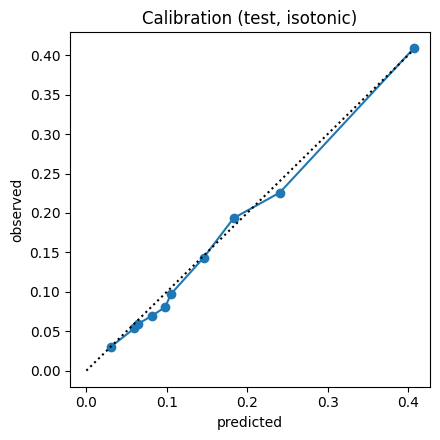

In [17]:
from sklearn.isotonic import IsotonicRegression
best_key = max(PRED, key=lambda k: roc_auc_score(y[va], PRED[k][0])); pv, pt = PRED[best_key]
print('best by validation AUC:', best_key)
iso = IsotonicRegression(out_of_bounds='clip').fit(pv, y[va]); pt_cal = iso.predict(pt)
print(f'Brier raw {brier_score_loss(y[te], pt):.4f} -> calibrated {brier_score_loss(y[te], pt_cal):.4f} (no-skill {brier_score_loss(y[te], np.full(len(te), prior)):.4f})')

hi_cut, med_cut = np.quantile(pv, 0.90), np.quantile(pv, 0.70)
band = np.where(pt >= hi_cut, 'high', np.where(pt >= med_cut, 'medium', 'low'))
bt = pd.DataFrame({'band': band, 'y': y[te]}).groupby('band').y.agg(patients='size', readmit_rate='mean', readmits='sum').reindex(['high', 'medium', 'low'])
bt['share_of_all_readmits'] = bt.readmits / y[te].sum(); print('\nRisk bands on the test set:'); print(bt.round(3).to_string())

rows = []
for q in [0.05, 0.10, 0.20, 0.30]:
    thr = np.quantile(pv, 1 - q); f = pt >= thr
    rows.append(dict(flag_top=f'{int(q * 100)}%', precision=y[te][f].mean(), recall=y[te][f].sum() / y[te].sum(), lift=y[te][f].mean() / y[te].mean()))
print('\nIf the hospital reviews only the top-risk patients:'); print(pd.DataFrame(rows).round(3).to_string(index=False))

qs = pd.qcut(pt_cal, 10, duplicates='drop'); cal = pd.DataFrame({'p': pt_cal, 'y': y[te], 'b': qs}).groupby('b').agg(pred=('p', 'mean'), obs=('y', 'mean'))
plt.figure(figsize=(4.5, 4.5)); plt.plot(cal.pred, cal.obs, 'o-'); plt.plot([0, cal.pred.max()], [0, cal.pred.max()], 'k:'); plt.xlabel('predicted'); plt.ylabel('observed')
plt.title('Calibration (test, isotonic)'); plt.tight_layout(); plt.savefig(os.path.join(OUT, 'calibration.png'), dpi=150); plt.show()

## 16. Save artifacts for the FastAPI / Streamlit app

In [18]:
ART = os.path.join(OUT, 'artifacts'); os.makedirs(ART, exist_ok=True)
for (name, rag), m in MODELS.items():
    if name == 'LogReg': joblib.dump(m, os.path.join(ART, f'logreg_{"rag" if rag else "base"}.joblib'))
DEPLOY = ('LogReg', False)    # simple, fast, explainable. Use ('LogReg', True) to score with the RAG feature as well
pv_d = PRED[DEPLOY][0]
iso_d = IsotonicRegression(out_of_bounds='clip').fit(pv_d, y[va]); joblib.dump(iso_d, os.path.join(ART, 'isotonic.joblib'))
hi_d, med_d = float(np.quantile(pv_d, 0.90)), float(np.quantile(pv_d, 0.70))
np.save(os.path.join(ART, 'corpus_embeddings.npy'), E[corpus_idx].astype(np.float16))
cases = df.iloc[corpus_idx][['admission_id', 'note']].assign(readmitted_30d=y[corpus_idx]); cases.to_csv(os.path.join(ART, 'corpus_cases.csv'), index=False)
cfg_out = dict(best_k=BEST_K, prior=float(prior), smooth_m=CFG['SMOOTH_M'], balance=BAL, embed_backend=CFG['EMBED_BACKEND'], embed_model=CFG['EMBED_MODEL'],
               num=NUM, cat=CAT, rag_cols=RAG_COLS, deployed_model=[DEPLOY[0], bool(DEPLOY[1])], risk_cut_high=hi_d, risk_cut_medium=med_d, style_noise=CFG['STYLE_NOISE'], seed=CFG['SEED'])
dx_options = diagnoses.diag_desc.value_counts().head(120).index.tolist()
dx_map = diagnoses.groupby('diag_desc').diag_category.agg(lambda s: s.mode().iat[0]).to_dict()
cfg_out.update(cat_values={c: sorted(df[c].astype(str).unique().tolist()) for c in CAT + ['patient_state', 'hospital_state']},
               dx_options=dx_options, dx_to_cat={d: dx_map[d] for d in dx_options},
               num_defaults={c: float(np.nan_to_num(df[c].median())) for c in NUM})
json.dump(cfg_out, open(os.path.join(ART, 'config.json'), 'w'), indent=2)
import shutil
RES.groupby(['model', 'rag'])[metric_cols].mean().round(4).reset_index().to_csv(os.path.join(ART, 'results_flat.csv'), index=False)
for f in ['rag_effect.csv', 'balancing_study.csv', 'curves.png', 'time_analysis.png', 'calibration.png', 'rolling_origin.png']:
    if os.path.exists(os.path.join(OUT, f)): shutil.copy(os.path.join(OUT, f), os.path.join(ART, f))
print(sorted(os.listdir(ART))); print('deployed model:', DEPLOY, '| risk cut-offs (raw LR probability): high >=', round(hi_d, 4), ', medium >=', round(med_d, 4))
print('To download: !zip -r outputs.zip outputs  (Colab), then use the files in the API/Streamlit app')

['balancing_study.csv', 'calibration.png', 'config.json', 'corpus_cases.csv', 'corpus_embeddings.npy', 'curves.png', 'isotonic.joblib', 'logreg_base.joblib', 'logreg_rag.joblib', 'rag_effect.csv', 'results_flat.csv', 'rolling_origin.png', 'time_analysis.png']
deployed model: ('LogReg', False) | risk cut-offs (raw LR probability): high >= 0.2699 , medium >= 0.1369
To download: !zip -r outputs.zip outputs  (Colab), then use the files in the API/Streamlit app


## 17. How to read these results (for the deck)
* **Fundamentals:** audit and leakage checklist passed; temporal split; rolling-origin AUC shows stability across years.
* **Time:** note the drift (PSI) table and the censoring check; if the last month's rate drops sharply, mention label censoring.
* **Balancing:** ranking metrics (AUC, PR-AUC) move little across strategies; balancing mainly changes recall/precision at a fixed threshold and inflates raw probabilities, which the isotonic step repairs.
* **RAG:** the notes are derived from the same structured fields, so expect a small or zero RAG effect; report the bootstrap CI honestly. If the CI includes zero, say so.
* **Deployment:** use the saved LogReg + corpus embeddings + `config.json` in the API; show retrieved similar cases as the explanation panel.